### Importación de librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Importación de los datos

El dataset utilizado está disponible en Kaggle en el siguiente enlace:

https://www.kaggle.com/datasets/shashwatwork/dataco-smart-supply-chain-for-big-data-analysis

Una vez descargado, cargamos los datos en un DataFrame:

In [2]:
df=pd.read_csv("DataCoSupplyChainDataset.csv", encoding="latin1")

In [3]:
df.head(1)

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.25,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class


### Limpieza y comprobación de los datos

In [4]:
df.shape

(180519, 53)

El dataframe está compuesto por 180519 filas y 53 columnas

In [5]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

Reducimos el número de columnas, seleccionando las más interesantes para nuestro análisis

In [6]:
df2=df[["Order Id","Type","order date (DateOrders)","shipping date (DateOrders)","Days for shipping (real)","Days for shipment (scheduled)",
        "Delivery Status","Late_delivery_risk","Shipping Mode","Market","Order Region","Order Country","Order State","Order City","Category Name",
        "Benefit per order","Order Status","Product Status"]].copy()

In [7]:
df2.dtypes

Order Id                           int64
Type                              object
order date (DateOrders)           object
shipping date (DateOrders)        object
Days for shipping (real)           int64
Days for shipment (scheduled)      int64
Delivery Status                   object
Late_delivery_risk                 int64
Shipping Mode                     object
Market                            object
Order Region                      object
Order Country                     object
Order State                       object
Order City                        object
Category Name                     object
Benefit per order                float64
Order Status                      object
Product Status                     int64
dtype: object

Las categorías "order date" y "shipping date" deben transformarse a tipo fecha:

In [8]:
df2["order date (DateOrders)"] = pd.to_datetime(df2["order date (DateOrders)"])
df2["shipping date (DateOrders)"] = pd.to_datetime(df2["shipping date (DateOrders)"])
df2.rename(columns={"order date (DateOrders)":"Order date","shipping date (DateOrders)":"Shipping date"},inplace=True)

In [9]:
df2.dtypes

Order Id                                  int64
Type                                     object
Order date                       datetime64[ns]
Shipping date                    datetime64[ns]
Days for shipping (real)                  int64
Days for shipment (scheduled)             int64
Delivery Status                          object
Late_delivery_risk                        int64
Shipping Mode                            object
Market                                   object
Order Region                             object
Order Country                            object
Order State                              object
Order City                               object
Category Name                            object
Benefit per order                       float64
Order Status                             object
Product Status                            int64
dtype: object

A continuación, comprobamos si hay duplicados y nulos: 

In [10]:
df2.duplicated().sum()

np.int64(18)

Aparecen 18 filas duplicadas (36 en total), por lo que vamos a investigarlas: 

In [11]:
duplicados = df2[df2.duplicated(keep=False)]

duplicados.sort_values(by="Order Id").head(10)

,Order Id,Type,Order date,Shipping date,Days for shipping (real),Days for shipment (scheduled),Delivery Status,Late_delivery_risk,Shipping Mode,Market,Order Region,Order Country,Order State,Order City,Category Name,Benefit per order,Order Status,Product Status
169892,791,TRANSFER,2015-01-12 12:46:00,2015-01-14 12:46:00,2,2,Shipping on time,0,Second Class,LATAM,South America,Bolivia,Potosí,Potosí,Women's Apparel,7.50,PROCESSING,0
169610,791,TRANSFER,2015-01-12 12:46:00,2015-01-14 12:46:00,2,2,Shipping on time,0,Second Class,LATAM,South America,Bolivia,Potosí,Potosí,Women's Apparel,7.50,PROCESSING,0
24908,2596,DEBIT,2015-02-07 21:08:00,2015-02-09 21:08:00,2,1,Late delivery,1,First Class,LATAM,Central America,El Salvador,San Salvador,San Salvador,Fishing,0.00,COMPLETE,0
24916,2596,DEBIT,2015-02-07 21:08:00,2015-02-09 21:08:00,2,1,Late delivery,1,First Class,LATAM,Central America,El Salvador,San Salvador,San Salvador,Fishing,0.00,COMPLETE,0
75901,4892,PAYMENT,2015-03-13 09:32:00,2015-03-16 09:32:00,3,4,Advance shipping,0,Standard Class,LATAM,Central America,México,Sinaloa,Culiacán,Water Sports,0.00,PENDING_PAYMENT,0
75902,4892,PAYMENT,2015-03-13 09:32:00,2015-03-16 09:32:00,3,4,Advance shipping,0,Standard Class,LATAM,Central America,México,Sinaloa,Culiacán,Water Sports,0.00,PENDING_PAYMENT,0
119590,7032,TRANSFER,2015-04-13 15:16:00,2015-04-16 15:16:00,3,2,Late delivery,1,Second Class,LATAM,Caribbean,Cuba,Isla de la Juventud,Nueva Gerona,Cleats,0.00,PENDING,0
119589,7032,TRANSFER,2015-04-13 15:16:00,2015-04-16 15:16:00,3,2,Late delivery,1,Second Class,LATAM,Caribbean,Cuba,Isla de la Juventud,Nueva Gerona,Cleats,0.00,PENDING,0
178684,7529,DEBIT,2015-04-20 21:23:00,2015-04-25 21:23:00,5,4,Late delivery,1,Standard Class,LATAM,Caribbean,Cuba,Santiago de Cuba,Santiago de Cuba,Indoor/Outdoor Games,20.58,COMPLETE,0
178683,7529,DEBIT,2015-04-20 21:23:00,2015-04-25 21:23:00,5,4,Late delivery,1,Standard Class,LATAM,Caribbean,Cuba,Santiago de Cuba,Santiago de Cuba,Indoor/Outdoor Games,20.58,COMPLETE,0


In [12]:
df2["Order Id"].nunique()

65752

In [13]:
len(df2)

180519

**Ajuste de la granularidad**

El dataset original está estructurado a nivel de línea de pedido, por lo que un mismo Order Id puede aparecer varias veces si contiene varios productos. Dado que el objetivo principal del análisis es estudiar el rendimiento de las entregas, se trabajará a nivel de pedido para evitar contar varias veces una misma entrega. Se conservará una sola fila por Order Id y se agregará la información de categorías asociadas a cada pedido

Primero creamos un nuevo dataframe en el que agrupamos df2 por Order Id y creamos una nueva columna que sea el resultado de agregar las columnas independientes de cada pedido:

In [14]:
df_pedidos=df2.groupby("Order Id")["Category Name"].agg(lambda x:", ".join(sorted(set(x)))).reset_index()

In [15]:
len(df_pedidos)

65752

Después creamos un segundo dataframe en el que eliminamos los duplicados de df2 para tener una solo línea por pedido y eliminamos la columna individual de "Category Name":

In [16]:
df_orders = df2.drop_duplicates(subset="Order Id").copy().drop(columns="Category Name")

Finalmente unimos ambos dataframes: 

In [17]:
df_final = df_orders.merge(df_pedidos,on="Order Id",how="left")

In [18]:
df_final.sort_values(by="Order Id").head(5)

,Order Id,Type,Order date,Shipping date,Days for shipping (real),Days for shipment (scheduled),Delivery Status,Late_delivery_risk,Shipping Mode,Market,Order Region,Order Country,Order State,Order City,Benefit per order,Order Status,Product Status,Category Name
19237,1,CASH,2015-01-01 00:00:00,2015-01-03 00:00:00,2,4,Advance shipping,0,Standard Class,LATAM,Central America,México,Distrito Federal,Mexico City,88.790001,CLOSED,0,Camping & Hiking
38360,2,PAYMENT,2015-01-01 00:21:00,2015-01-04 00:21:00,3,4,Advance shipping,0,Standard Class,LATAM,South America,Colombia,Risaralda,Dos Quebradas,91.180000,PENDING_PAYMENT,0,"Men's Footwear, Water Sports, Women's Apparel"
32995,4,CASH,2015-01-01 01:03:00,2015-01-06 01:03:00,5,4,Late delivery,1,Standard Class,LATAM,South America,Colombia,Risaralda,Dos Quebradas,4.100000,CLOSED,0,"Accessories, Cleats, Indoor/Outdoor Games, Wom..."
12435,5,DEBIT,2015-01-01 01:24:00,2015-01-07 01:24:00,6,4,Late delivery,1,Standard Class,LATAM,South America,Colombia,Risaralda,Dos Quebradas,34.939999,COMPLETE,0,"Camping & Hiking, Cleats, Indoor/Outdoor Games..."
33491,7,DEBIT,2015-01-01 02:06:00,2015-01-04 02:06:00,3,2,Late delivery,1,Second Class,LATAM,South America,Brasil,São Paulo,São Paulo,120.949997,COMPLETE,0,"Camping & Hiking, Trade-In, Water Sports"


In [19]:
df_final.shape

(65752, 18)

In [20]:
df_final["Order Id"].nunique()

65752

In [21]:
df_final.duplicated().sum()

np.int64(0)

Tras revisar la granularidad del dataset, se comprobó que las 180.519 filas originales correspondían a 65.752 pedidos únicos, ya que un mismo pedido podía contener varias líneas de producto.Para evitar contar varias veces una misma entrega, se transformó el dataset a nivel de pedido, conservando una única fila por Order Id. Las categorías de producto asociadas a cada pedido se agregaron en una sola variable para no perder esta información.

A continuación revisamos si hay valores nulos:

In [22]:
df_final.isna().sum()

Order Id                         0
Type                             0
Order date                       0
Shipping date                    0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Delivery Status                  0
Late_delivery_risk               0
Shipping Mode                    0
Market                           0
Order Region                     0
Order Country                    0
Order State                      0
Order City                       0
Benefit per order                0
Order Status                     0
Product Status                   0
Category Name                    0
dtype: int64

Vamos a comprobar los valores únicos de algunas columnas categóricas: 

In [23]:
df_final.nunique()

Order Id                         65752
Type                                 4
Order date                       65752
Shipping date                    63701
Days for shipping (real)             7
Days for shipment (scheduled)        4
Delivery Status                      4
Late_delivery_risk                   2
Shipping Mode                        4
Market                               5
Order Region                        23
Order Country                      164
Order State                       1089
Order City                        3597
Benefit per order                15892
Order Status                         9
Product Status                       1
Category Name                     4612
dtype: int64

In [24]:
df_final["Type"].unique()

array(['DEBIT', 'TRANSFER', 'CASH', 'PAYMENT'], dtype=object)

In [25]:
df_final["Delivery Status"].unique()

array(['Advance shipping', 'Late delivery', 'Shipping on time',
       'Shipping canceled'], dtype=object)

In [26]:
df_final["Shipping Mode"].unique()

array(['Standard Class', 'First Class', 'Second Class', 'Same Day'],
      dtype=object)

In [27]:
df_final["Market"].unique()

array(['Pacific Asia', 'USCA', 'Africa', 'Europe', 'LATAM'], dtype=object)

In [28]:
df_final["Order Status"].unique()

array(['COMPLETE', 'PENDING', 'CLOSED', 'PENDING_PAYMENT', 'CANCELED',
       'PROCESSING', 'SUSPECTED_FRAUD', 'ON_HOLD', 'PAYMENT_REVIEW'],
      dtype=object)

In [29]:
df_final["Product Status"].unique()

array([0])

Eliminamos la columna Product Status porque tiene un único valor común a todos los pedidos

In [30]:
df_final.drop(columns="Product Status", inplace=True)

### Análisis exploratorio y descriptivo

Una vez preparados los datos, se realiza un análisis exploratorio con el objetivo de comprender el comportamiento general de las entregas e identificar posibles patrones asociados a los retrasos.

Primero calculamos la tasa de pedidos con retraso. En el glosario de términos, indican: 
"Late_delivery_risk:  Categorical variable that indicates if sending is late (1), it is not late (0)."

In [31]:
df_final["Late_delivery_risk"].value_counts(normalize=True).round(4)*100

Late_delivery_risk
1    54.82
0    45.18
Name: proportion, dtype: float64

El **54.82% de los pedidos sufren retraso**. Es un porcentaje bastante alto, lo que indica que el retraso representa un problema relevante de rendimiento logístico.

Veamos cómo se desglosan los pedidos sin retraso:

In [32]:
df_final["Delivery Status"].value_counts(normalize=True).round(4)*100

Delivery Status
Late delivery        54.82
Advance shipping     23.01
Shipping on time     17.83
Shipping canceled     4.34
Name: proportion, dtype: float64

Del 45,18 % restante de los pedidos que fueron entregados sin retraso, aproximadamente un **23 % llegó antes de la fecha prevista**, un **17,83 % llegó a tiempo** y un **4,34 % fue cancelado**.

A continuación, vamos a estudiar la posible relación de cada una de las variables seleccionadas con "Late_delivery_risk". Esta variable es binaria, donde 1 indica que el pedido llegó tarde y 0 que no hubo retraso. Para realizarlo de manera ordenada, primeramente vamos a estudiar las variables numéricas mediante la matriz de correlación de Pearson, la cual permite medir la fuerza y dirección de la relación lineal entre variables. Sus valores oscilan entre -1 y 1: valores positivos indican que ambas variables tienden a aumentar juntas, valores negativos indican que cuando una aumenta la otra tiende a disminuir, y valores cercanos a 0 reflejan ausencia de una relación lineal clara.

<Axes: >

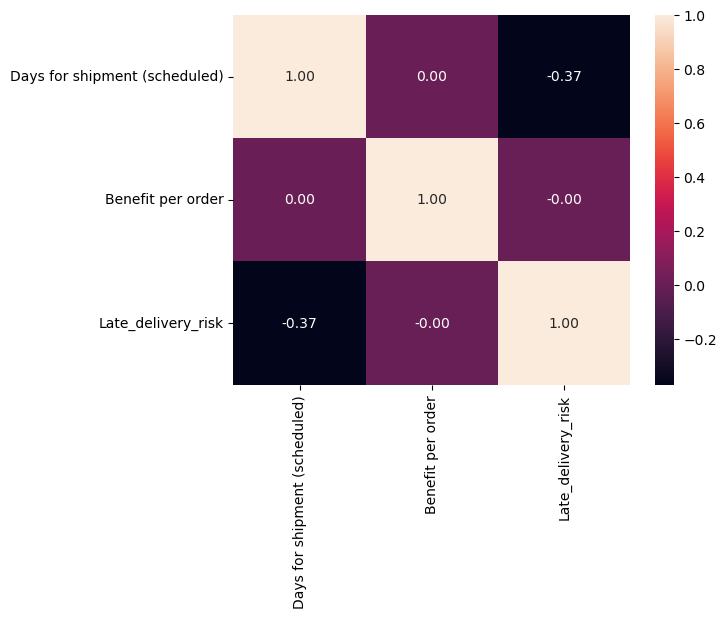

In [33]:
#Creamos una lista con los nombres de las columnas que queremos analizar:
variables_numericas = ["Days for shipment (scheduled)","Benefit per order","Late_delivery_risk"]

#Calculamos la correlación de Pearson entre las columnas seleccionadas
corr = df_final[variables_numericas].corr()

#Representamos la matriz de correlación con un mapa de calor
sns.heatmap(corr, annot=True, fmt=".2f")

En este caso, Days for shipment (scheduled) presenta una correlación de aproximadamente -0,37 con Late_delivery_risk, lo que sugiere que los pedidos con plazos programados más amplios tienden a presentar una menor probabilidad de retraso. En cambio, Benefit per order muestra correlación prácticamente nula con el retraso.

A continuación, vamos a estudiar la relación entre Late_delivery_risk y las variables categóricas mediante la V de Cramer, una medida que permite cuantificar la fuerza de asociación entre dos variables categóricas. Sus valores oscilan entre 0 y 1: valores próximos a 0 indican una asociación débil o inexistente, mientras que valores próximos a 1 indican una asociación fuerte. Para calcularla, primero se construye una tabla de contingencia, que recoge el número de casos correspondientes a cada combinación de categorías de las dos variables. A continuación, se calcula el estadístico chi-cuadrado, que compara los recuentos observados con los que se esperarían si ambas variables fueran independientes. Finalmente, a partir del valor de chi-cuadrado, del tamaño de la muestra y del número de categorías, se obtiene la V de Cramer.

In [34]:
from scipy.stats import chi2_contingency

def cramers_v(var1, var2):
    #Creamos una tabla de contingencia entre las dos variables
    tabla = pd.crosstab(var1, var2)
    #Calculamos chi-cuadrado 
    chi2 = chi2_contingency(tabla)[0]
    #Calculamos el número total de observaciones
    n = tabla.sum().sum()
    #Guardamos el número de filas y columnas de la tabla
    r, k = tabla.shape

    #Devolvemos el valor de la V de Cramer
    return np.sqrt((chi2 / n) / min(k - 1, r - 1))

In [35]:
#Guardamos el nombre de cada una de las columnas categóricas cuya relación queremos analizar. 

variables_categoricas = ["Type","Shipping Mode","Market","Order Region","Order Country"]

In [36]:
resultados_cramer = {}

#Para cada variable, aplicamos la función cramers_v:

for col in variables_categoricas:
    resultados_cramer[col] = cramers_v(df_final[col],df_final["Late_delivery_risk"])

In [37]:
#Visualizamos los resultados en forma de serie ordenada

pd.Series(resultados_cramer).sort_values(ascending=False)

Shipping Mode    0.455824
Type             0.082368
Order Country    0.053414
Order Region     0.021904
Market           0.007796
dtype: float64

Vemos que Shipping Mode es la variable categórica que presenta una mayor asociación con Late_delivery_risk, con una V de Cramér de aproximadamente 0,46. El resto de variables muestran una asociación muy débil o prácticamente nula, desde 0,08 para Type hasta 0,008 para Market.

De esta primera evaluación extraemos que las variables que muestran una mayor asociación con el retraso son Days for shipment (scheduled) y Shipping Mode. Vamos a analizar más en detalle el desglose de pedidos retrasados en función de estas dos variables:

In [38]:
df_final.groupby("Shipping Mode")["Late_delivery_risk"].mean().round(4) * 100

Shipping Mode
First Class       95.27
Same Day          46.15
Second Class      76.72
Standard Class    38.13
Name: Late_delivery_risk, dtype: float64

**Las mayores tasas de retraso corresponden a First Class y Second Class**, con un 95,27 % y un 76,72 %, respectivamente. En cambio, Same Day presenta una tasa de retraso del 46,15 % y Standard Class del 38,13 %. Estos resultados muestran diferencias importantes en el cumplimiento de los plazos entre los distintos modos de envío.

In [39]:
df_final.groupby("Days for shipment (scheduled)")["Late_delivery_risk"].mean().round(4) * 100

Days for shipment (scheduled)
0    46.15
1    95.27
2    76.72
4    38.13
Name: Late_delivery_risk, dtype: float64

**Los pedidos que mayores retrasos muestran son aquellos con uno (95.27% de retraso) o dos días (76.72%) de envío previsto**. Los que se preveen ser enviados el mismo día (46.15%) o en 4 días (38.13%) presentan menor porcentaje de retraso. 

Dado que los porcentajes obtenidos en estas dos variables son idénticos, vamos a ver la relación entre ellas:

In [40]:
pd.crosstab(df_final["Shipping Mode"],df_final["Days for shipment (scheduled)"])

Days for shipment (scheduled),0,1,2,4
Shipping Mode,,,,
First Class,0,10079,0,0
Same Day,3571,0,0,0
Second Class,0,0,12778,0
Standard Class,0,0,0,39324


Cada modo de envío está asociado a una única previsión de días de envío. Por tanto, Shipping Mode y Days for shipment (scheduled) representan esencialmente la misma información.

Por último, para evaluar la posible existencia de estacionalidad, vamos a analizar de la misma manera la tasa de retraso a lo largo de los distintos meses:

In [41]:
df_final["Order month"] = df_final["Order date"].dt.month

In [42]:
df_final.groupby("Order month")["Late_delivery_risk"].mean().round(4) * 100

Order month
1     55.15
2     54.51
3     55.36
4     53.71
5     54.79
6     55.39
7     53.82
8     55.32
9     55.07
10    54.60
11    54.64
12    55.34
Name: Late_delivery_risk, dtype: float64

La tasa de retraso se mantiene estable a lo largo del año, situándose aproximadamente entre el 53 % y el 56 % en todos los meses. Por tanto, **no se observa una relación clara entre el mes en que se realiza el pedido y la probabilidad de retraso**.

Veamos qué ocurre con el registro histórico año-mes:

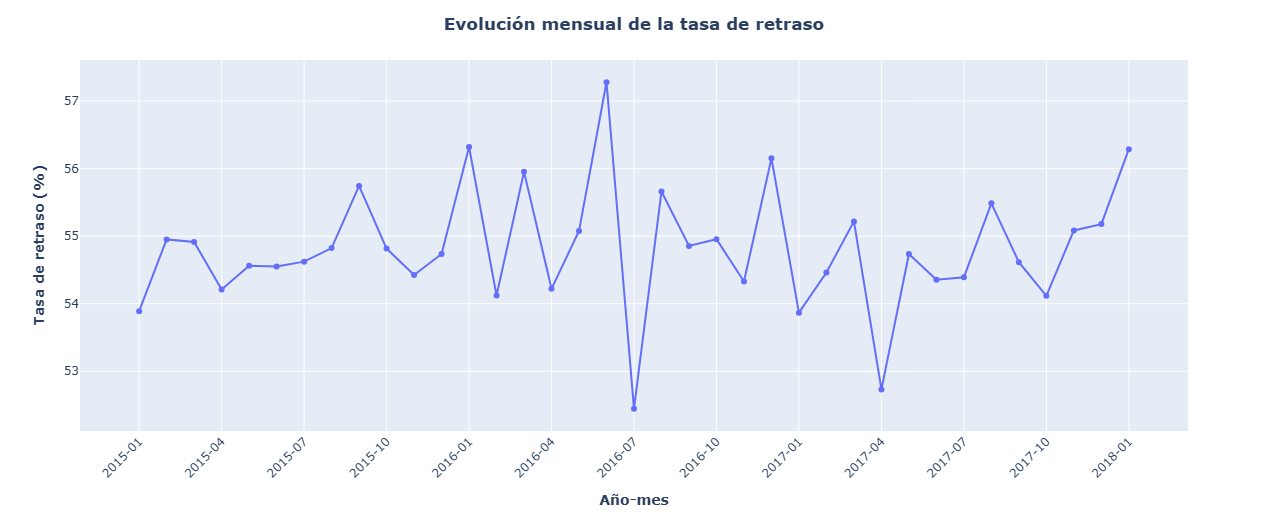

In [43]:
#Importamos la libería plotly.express para hacer un gráfico interactivo
import plotly.express as px

# Creamos una columna que contenga la fecha en formato texto como AAAA-MM
df_final["Order year_month"] = (df_final["Order date"].dt.to_period("M").astype(str))

# Calculamos la media de retraso por cada combinación año-mes 
retraso_mensual = (df_final.groupby("Order year_month")["Late_delivery_risk"].mean().mul(100).reset_index())

# Creamos el gráfico
fig = px.line(retraso_mensual,x="Order year_month",y="Late_delivery_risk",markers=True)

# Personalizamos el eje X
fig.update_xaxes(
    type="category",
    tickmode="array",
    tickvals=retraso_mensual["Order year_month"][::3],
    ticktext=retraso_mensual["Order year_month"][::3],
    tickangle=-45,
    title="<b>Año-mes</b>"
)

# Personalizamos el eje Y
fig.update_yaxes(title="<b>Tasa de retraso (%)</b>")

# Personalizamos el título y el tamaño
fig.update_layout(
    title={"text": "<b>Evolución mensual de la tasa de retraso</b>","x": 0.5},
    height=500,
    width=1300
)

# Personalizamos la información mostrada al pasar el cursor
fig.update_traces(
    hovertemplate=
        "<b>Mes:</b> %{x}<br>"
        "<b>Tasa de retraso:</b> %{y:.2f}%"
        )

fig.show()

La tasa mensual de retraso se mantiene relativamente estable durante el periodo analizado, situándose generalmente entre el 54 % y el 56 %. Aunque se observan algunas fluctuaciones puntuales, especialmente en junio y julio de 2016 y abril de 2017, no se aprecia una tendencia creciente o decreciente sostenida ni un patrón temporal claro en la tasa de retraso.

**Conclusión**

El análisis descriptivo muestra que Shipping Mode es la variable con mayor asociación con Late_delivery_risk. La variable Days for shipment (scheduled) también presenta una asociación relevante, aunque ambas contienen esencialmente la misma información, ya que cada modo de envío está asociado a un único número de días programados. El resto de variables analizadas presentan asociaciones débiles o prácticamente nulas, y tampoco se observa un patrón temporal claro en la tasa de retraso.

### Análisis predictivo

Una vez identificados los principales patrones asociados a los retrasos, se realizará un análisis predictivo con el objetivo de estimar si un pedido llegará tarde a partir de información disponible antes de la entrega. Dado que Late_delivery_risk es una variable binaria (0 = sin retraso, 1 = retraso), el problema se plantea como una tarea de clasificación.

Vamos a plantear un primer modelo de regresión logística usando solo Shipping Mode como predictor. El primer paso consiste en convertir Shipping Mode a variables dummy que pueda entender el modelo:

In [44]:
X=pd.get_dummies(df_final["Shipping Mode"], drop_first=True)

In [45]:
X.head()

,Same Day,Second Class,Standard Class
0,False,False,True
1,False,False,True
2,False,False,True
3,False,False,True
4,False,False,True


Y definimos Late_delivery_risk como variable objetivo:

In [46]:
y=df_final["Late_delivery_risk"]

In [47]:
y.head()

0    0
1    1
2    0
3    0
4    0
Name: Late_delivery_risk, dtype: int64

A continuación, dividimos el conjunto de datos en set de entrenamiento (80%) y set de prueba (20%):

In [48]:
from sklearn.model_selection import train_test_split

In [49]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Importamos el modelo de Regresión Logística y lo entrenamos:

In [50]:
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression()

modelo.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


Predecimos los valores de "Late_delivery_risk" y evaluamos el modelo:

In [51]:
y_pred = modelo.predict(X_test)

In [52]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

accuracy = accuracy_score(y_test, y_pred)
accuracy

0.691582389171926

**El modelo acierta el 69% de los pedidos.**

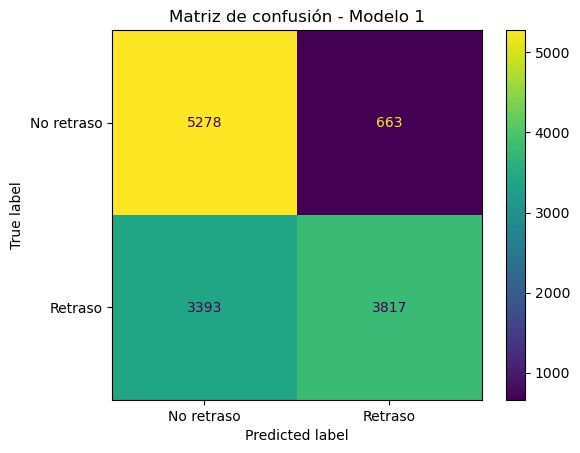

In [53]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No retraso", "Retraso"]
)

plt.title("Matriz de confusión - Modelo 1")
plt.show()

5278 pedidos fueron correctamente clasificados como sin retraso y 3817 pedidos como con retraso. Por el contrario, 663 pedidos fueron erróneamente clasificados como con retraso y 3393 como sin retraso. El mayor punto a destacar es que **el modelo está clasificando mal muchos pedidos que realmente sí sufren retraso.** 

In [54]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.61      0.89      0.72      5941
           1       0.85      0.53      0.65      7210

    accuracy                           0.69     13151
   macro avg       0.73      0.71      0.69     13151
weighted avg       0.74      0.69      0.68     13151



**El modelo identifica bien los pedidos sin retraso** (recall = 0.89) y **cuando predice un retraso suele acertar** (precision = 0.85). Sin embargo, **solo detecta el 53 % de los retrasos reales**, por lo que deja sin identificar una proporción importante de pedidos que finalmente llegan tarde.

Vamos a crear un segundo modelo de predicción incluyendo la variable Type, que era la única variable categórica restante con cierta asociación con Late_delivery_risk, aunque débil. El objetivo es comprobar si su incorporación mejora el rendimiento respecto al primer modelo basado únicamente en Shipping Mode. Para ello, repetimos el mismo procedimiento:

In [55]:
X2=pd.get_dummies(df_final[["Shipping Mode","Type"]], drop_first=True)

In [56]:
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [57]:
modelo2 = LogisticRegression()
modelo2.fit(X2_train, y2_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [58]:
y2_pred = modelo2.predict(X2_test)

In [59]:
accuracy = accuracy_score(y2_test, y2_pred)
accuracy

0.691582389171926

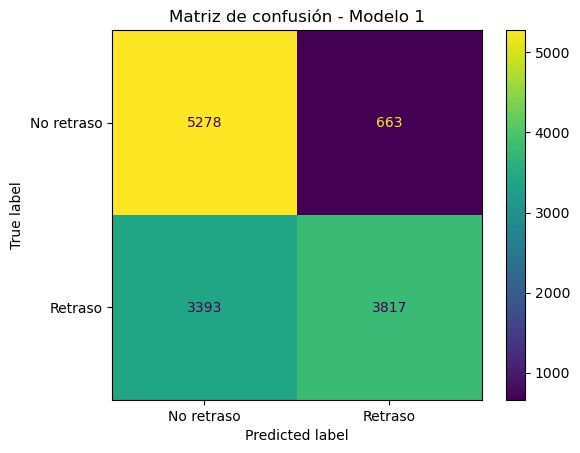

In [60]:
ConfusionMatrixDisplay.from_predictions(
    y2_test,
    y2_pred,
    display_labels=["No retraso", "Retraso"]
)

plt.title("Matriz de confusión - Modelo 1")
plt.show()

In [61]:
print(classification_report(y2_test, y2_pred))

              precision    recall  f1-score   support

           0       0.61      0.89      0.72      5941
           1       0.85      0.53      0.65      7210

    accuracy                           0.69     13151
   macro avg       0.73      0.71      0.69     13151
weighted avg       0.74      0.69      0.68     13151



**La incorporación de Type no mejora la capacidad de clasificación del modelo**, lo que confirma que su débil asociación observada en el análisis descriptivo no aporta valor predictivo adicional relevante frente a Shipping Mode.

A continuación, vamos a repetir el estudio con otro modelo de Machine Learning, para comprobar si mejora la predicción: DecisionTreeClassifier.

In [62]:
from sklearn.tree import DecisionTreeClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

arbol = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)
arbol.fit(X_train, y_train)

y_pred = arbol.predict(X_test)

In [63]:
accuracy = accuracy_score(y_test, y_pred)
accuracy

0.691582389171926

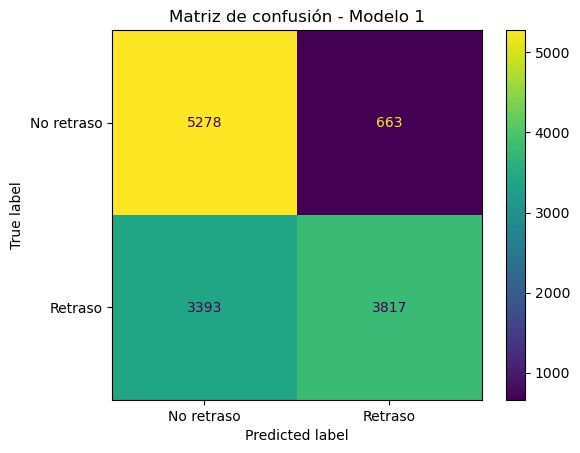

In [64]:
ConfusionMatrixDisplay.from_predictions(
    y2_test,
    y2_pred,
    display_labels=["No retraso", "Retraso"]
)

plt.title("Matriz de confusión - Modelo 1")
plt.show()

In [65]:
print(classification_report(y2_test, y2_pred))

              precision    recall  f1-score   support

           0       0.61      0.89      0.72      5941
           1       0.85      0.53      0.65      7210

    accuracy                           0.69     13151
   macro avg       0.73      0.71      0.69     13151
weighted avg       0.74      0.69      0.68     13151



**El modelo DecisionTreeClassifier no mejora el rendimiento** obtenido con la regresión logística y produce las mismas predicciones sobre el conjunto de prueba. Este resultado es coherente con la limitada información predictiva disponible en el dataset: tras el análisis exploratorio, Shipping Mode es prácticamente la única variable con una asociación relevante con Late_delivery_risk, mientras que el resto de variables aportan poca o ninguna señal adicional. Por tanto, la principal limitación del modelo no parece residir en el algoritmo utilizado, sino en la escasez de variables capaces de explicar o anticipar los retrasos.

### Conclusiones

**Principales resultados**

- El 54,8 % de los pedidos presenta retraso.
- Shipping Mode es la variable con mayor asociación con Late_delivery_risk (V de Cramér ≈ 0,46).
- First Class y Second Class presentan las mayores tasas de retraso.
- Shipping Mode y Days for shipment (scheduled) contienen esencialmente la misma información.
- No se observa una relación relevante con mercado, región, país o periodo temporal.
- La regresión logística alcanza aproximadamente un 69,2 % de accuracy, pero solo identifica el 53 % de los retrasos reales.
- La incorporación de Type y el uso de un árbol de decisión no producen mejoras relevantes en la clasificación.


El análisis muestra que Shipping Mode es la variable con mayor asociación con Late_delivery_risk. Days for shipment (scheduled) también presenta relación con el retraso, aunque ambas variables contienen esencialmente la misma información, ya que cada modo de envío está asociado a un número fijo de días programados. El resto de variables analizadas presentan asociaciones débiles o prácticamente nulas, y tampoco se observa un patrón temporal claro.

En la parte predictiva, la regresión logística utilizando Shipping Mode obtuvo una accuracy del 69.2 %. Aunque presenta una precision de 0.85 para los retrasos, su recall es de 0.53, por lo que solo identifica algo más de la mitad de los retrasos reales. La incorporación de Type no mejoró las clasificaciones y el modelo de DecisionTreeClassifier produjo resultados prácticamente idénticos.

En conjunto, la principal limitación no parece estar en el algoritmo utilizado, sino en la escasez de variables con capacidad predictiva.

### Recomendaciones:
- Dado que Shipping Mode es la única variable que presenta una asociación clara con los retrasos, la empresa debería priorizar la revisión del cumplimiento de los distintos modos de envío, especialmente los asociados a First Class y Second Class, que son los que concentran las mayores tasas de retraso. El problema no parece estar en una zona geográfica concreta ni en una estacionalidad determinada, sino en el cumplimiento de determinados niveles de servicio.
- Mejorar la recogida de datos logísticos, incorporando variables como transportista, centro logístico, incidencias, etc. Esto permitiría identificar las causas reales de los retrasos y plantear acciones de mejora más específicas.